# Method 1 — Hand-crafted features (HOG + LBP + colour) with an SVM
CPS 4841 course project · EuroSAT land-use classification · Qiwen Xue

**Idea.** A traditional, non-deep-learning baseline. Every 64×64 image is turned into a fixed-length feature vector that describes its **shape/edges** (HOG), **texture** (LBP) and **colour** (HSV histograms + RGB mean/std). A support vector machine with an RBF kernel is trained on these vectors. The SVM's `C` is chosen on the validation split; the test split is used once, at the end.

**Run:** clone the repository, then run this notebook top to bottom (Colab or local). The first cell downloads the data if needed.

**Source and AI disclosure.** HOG [Dalal & Triggs, CVPR 2005], LBP [Ojala et al., TPAMI 2002] and the SVM come from scikit-image and scikit-learn. The notebook code was drafted with Claude (Anthropic, Claude Opus 5.5) and reviewed by me; see the README for details.

In [1]:
# Setup. In Colab, first run:
#   !git clone https://github.com/xueqw/eurosat-landuse-classification.git
#   %cd eurosat-landuse-classification
import os, time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from common import load_splits, compute_metrics, CLASSES

SEED = 42
np.random.seed(SEED)
os.makedirs('results', exist_ok=True)
df = load_splits()            # downloads EuroSAT on first run; fixed 70/15/15 split from splits.csv
print(df['split'].value_counts().reindex(['train', 'val', 'test']))

split
train    18900
val       4050
test      4050
Name: count, dtype: int64


## 1. Feature extraction
| Feature | Settings | Length | What it captures |
|---|---|---|---|
| HOG (grayscale) | 9 orientations, 8×8-pixel cells, 2×2-cell blocks, L2-Hys | 1,764 | edge directions, shapes (roads, field borders, buildings) |
| LBP histogram (grayscale) | uniform LBP, P = 8, R = 1 | 10 | fine texture (forest canopy vs. smooth water) |
| HSV histograms | 16 bins per channel, normalised | 48 | colour distribution |
| RGB statistics | mean and std of each channel | 6 | overall brightness and tint |
| **Total** | | **1,828** | |

In [2]:
# AI-assisted (Claude Opus 5.5): feature function drafted by the assistant; parameter choices reviewed by me.
from skimage.feature import hog, local_binary_pattern
from skimage.color import rgb2gray, rgb2hsv

def extract_features(path):
    rgb = np.asarray(Image.open(path).convert('RGB'))          # 64 x 64 x 3, uint8
    gray = rgb2gray(rgb)                                       # float in [0, 1]
    f_hog = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                cells_per_block=(2, 2), block_norm='L2-Hys')  # 7*7 blocks * 4 cells * 9 bins = 1764
    lbp = local_binary_pattern((gray * 255).astype(np.uint8), P=8, R=1, method='uniform')
    f_lbp, _ = np.histogram(lbp, bins=10, range=(0, 10), density=True)   # uniform LBP has 10 codes
    hsv = rgb2hsv(rgb)
    f_hsv = np.concatenate([np.histogram(hsv[..., c], bins=16, range=(0, 1))[0] for c in range(3)])
    f_hsv = f_hsv / f_hsv.sum()
    f_rgb = np.concatenate([rgb.mean((0, 1)), rgb.std((0, 1))]) / 255.0
    return np.concatenate([f_hog, f_lbp, f_hsv, f_rgb]).astype(np.float32)

# index ranges of each feature group inside the vector (used for the feature-group check below)
GROUPS = {'HOG': slice(0, 1764), 'LBP': slice(1764, 1774), 'Colour (HSV+RGB)': slice(1774, 1828)}

t0 = time.time()
X = np.stack([extract_features(p) for p in df['path']])
y = df['label_id'].to_numpy()
print('Feature matrix:', X.shape, f'({time.time() - t0:.1f} s, {1000 * (time.time() - t0) / len(X):.2f} ms per image)')
tr, va, te = [(df['split'] == s).to_numpy() for s in ('train', 'val', 'test')]   # boolean masks
print('train / val / test:', tr.sum(), va.sum(), te.sum())

Feature matrix: (27000, 1828) (31.6 s, 1.17 ms per image)
train / val / test: 18900 4050 4050


## 2. Choosing the SVM's C on the validation split
Features are standardised (zero mean, unit variance, fitted on the training split only). The RBF kernel width uses scikit-learn's default `gamma='scale'` = 1 / (n_features · Var(X)). Only the validation split is used to compare settings.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

def make_model(C):
    return make_pipeline(StandardScaler(), SVC(kernel='rbf', C=C, gamma='scale', random_state=SEED))

search = []
for C in [1, 3, 10, 30]:
    t0 = time.time()
    m = make_model(C).fit(X[tr], y[tr])
    scores = compute_metrics(y[va], m.predict(X[va]))
    search.append({'C': C, **scores, 'fit_seconds': round(time.time() - t0, 1)})
    print(search[-1])
search = pd.DataFrame(search)
search.to_csv('results/method1_val_search.csv', index=False)
best_C = float(search.loc[search['macro_f1'].idxmax(), 'C'])
print('Best C on validation (by macro F1):', best_C)
search.round(4)

{'C': 1, 'accuracy': 0.8481481481481481, 'macro_precision': 0.8450266126692508, 'macro_recall': 0.8417111111111112, 'macro_f1': 0.8425890969551931, 'fit_seconds': 140.9}


{'C': 3, 'accuracy': 0.8619753086419754, 'macro_precision': 0.860172157267541, 'macro_recall': 0.8559777777777778, 'macro_f1': 0.8570622098512771, 'fit_seconds': 131.7}


{'C': 10, 'accuracy': 0.8612345679012345, 'macro_precision': 0.859352389057913, 'macro_recall': 0.8552222222222223, 'macro_f1': 0.8562447471689689, 'fit_seconds': 148.1}


{'C': 30, 'accuracy': 0.8612345679012345, 'macro_precision': 0.859352389057913, 'macro_recall': 0.8552222222222223, 'macro_f1': 0.8562447471689689, 'fit_seconds': 148.4}
Best C on validation (by macro F1): 3.0


,C,accuracy,macro_precision,macro_recall,macro_f1,fit_seconds
0,1,0.8481,0.8450,0.8417,0.8426,140.9
1,3,0.8620,0.8602,0.8560,0.8571,131.7
2,10,0.8612,0.8594,0.8552,0.8562,148.1
3,30,0.8612,0.8594,0.8552,0.8562,148.4


## 3. Which features matter? (validation split, best C)
A quick check of each feature group on its own, to understand the baseline. This is analysis only; the final model uses all features.

In [4]:
rows = []
for name, sl in GROUPS.items():
    m = make_model(best_C).fit(X[tr][:, sl], y[tr])
    rows.append({'features': name, 'dims': sl.stop - sl.start, **compute_metrics(y[va], m.predict(X[va][:, sl]))})
rows.append({'features': 'All (final model)', 'dims': X.shape[1],
             **search.loc[search['C'] == best_C, ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].iloc[0].to_dict()})
groups = pd.DataFrame(rows)
groups.to_csv('results/method1_feature_groups_val.csv', index=False)
groups.round(4)

,features,dims,accuracy,macro_precision,macro_recall,macro_f1
0,HOG,1764,0.7074,0.7027,0.6942,0.6960
1,LBP,10,0.7617,0.7492,0.7521,0.7490
2,Colour (HSV+RGB),54,0.8281,0.8207,0.8228,0.8206
3,All (final model),1828,0.8620,0.8602,0.8560,0.8571


## 4. Final evaluation on the test split
The model with the chosen `C` is trained on the training split and evaluated **once** on the 4,050 test images.

In [5]:
t0 = time.time()
final = make_model(best_C).fit(X[tr], y[tr])
train_time = time.time() - t0
t0 = time.time()
y_pred = final.predict(X[te])
pred_time = time.time() - t0
test_metrics = compute_metrics(y[te], y_pred)
summary = {'method': 'Method 1: HOG+LBP+colour features + RBF SVM', 'C': best_C,
           **{k: round(float(v), 4) for k, v in test_metrics.items()},
           'n_test': int(te.sum()), 'n_support_vectors': int(final[-1].n_support_.sum()),
           'train_seconds': round(train_time, 1),
           'predict_ms_per_image': round(1000 * pred_time / te.sum(), 3)}
with open('results/method1_test_metrics.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "method": "Method 1: HOG+LBP+colour features + RBF SVM",
  "C": 3.0,
  "accuracy": 0.8553,
  "macro_precision": 0.851,
  "macro_recall": 0.8484,
  "macro_f1": 0.849,
  "n_test": 4050,
  "n_support_vectors": 14505,
  "train_seconds": 83.3,
  "predict_ms_per_image": 13.332
}


In [6]:
from sklearn.metrics import classification_report, confusion_matrix
report = classification_report(y[te], y_pred, target_names=CLASSES, digits=4)
open('results/method1_classification_report.txt', 'w').write(report)
print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.7723    0.8667    0.8168       450
              Forest     0.9778    0.9778    0.9778       450
HerbaceousVegetation     0.7846    0.7933    0.7890       450
             Highway     0.7825    0.7387    0.7599       375
          Industrial     0.9439    0.9413    0.9426       375
             Pasture     0.8151    0.7933    0.8041       300
       PermanentCrop     0.7477    0.6480    0.6943       375
         Residential     0.8926    0.9422    0.9168       450
               River     0.8118    0.8053    0.8086       375
             SeaLake     0.9821    0.9778    0.9800       450

            accuracy                         0.8553      4050
           macro avg     0.8510    0.8484    0.8490      4050
        weighted avg     0.8546    0.8553    0.8542      4050



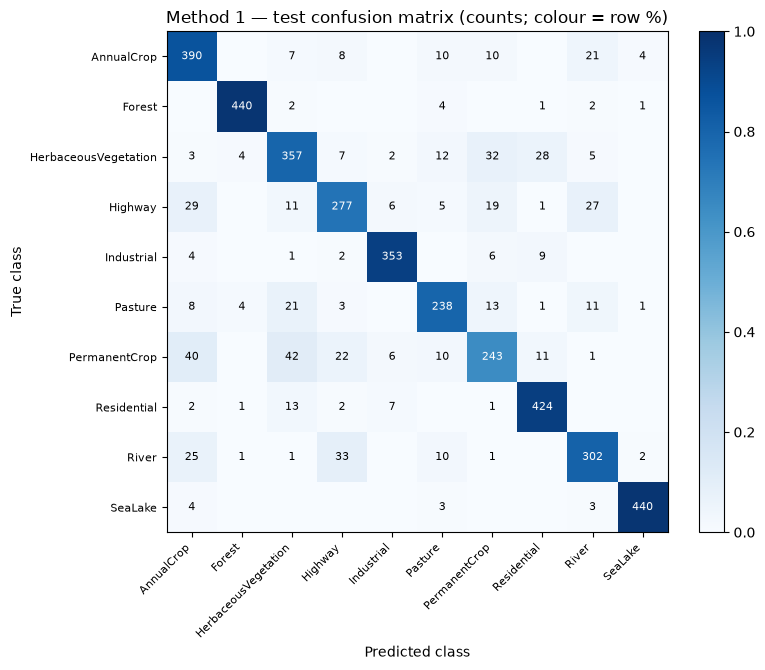

PermanentCrop -> HerbaceousVegetation    42
PermanentCrop -> AnnualCrop              40
River -> Highway                         33
HerbaceousVegetation -> PermanentCrop    32
Highway -> AnnualCrop                    29
HerbaceousVegetation -> Residential      28
Highway -> River                         27
River -> AnnualCrop                      25
Name: most frequent confusions, dtype: int64

In [7]:
cm = confusion_matrix(y[te], y_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                    color='white' if cm_norm[i, j] > 0.6 else 'black')
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(10), CLASSES, fontsize=8)
ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
ax.set_title('Method 1 — test confusion matrix (counts; colour = row %)')
fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig('results/method1_confusion_matrix.png', dpi=200); plt.show()
pd.Series({f'{CLASSES[i]} -> {CLASSES[j]}': cm[i, j] for i in range(10) for j in range(10) if i != j}).sort_values(ascending=False).head(8).rename('most frequent confusions')

## 5. A first look at mistakes
Random misclassified test images (true → predicted). The full error analysis (≥ 10 cases, grouped into failure patterns) is planned for the final report, on the best of the three methods.

586 of 4050 test images misclassified


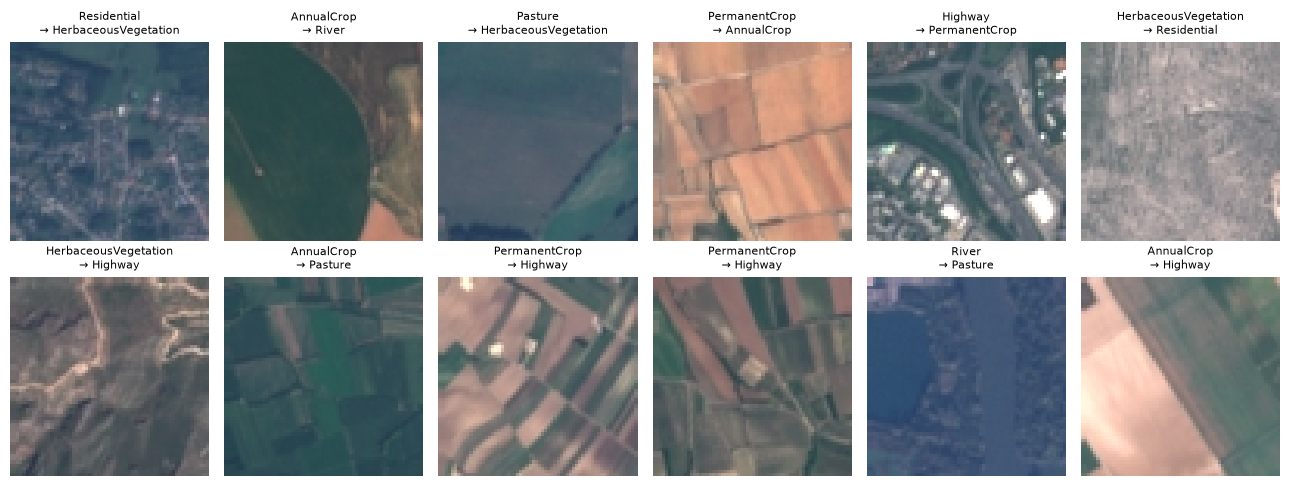

In [8]:
wrong = np.flatnonzero(y_pred != y[te])
test_paths = df.loc[te, 'path'].to_numpy()
print(f'{len(wrong)} of {te.sum()} test images misclassified')
pick = np.random.default_rng(0).choice(wrong, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, k in zip(axes.ravel(), pick):
    ax.imshow(Image.open(test_paths[k])); ax.axis('off')
    ax.set_title(f'{CLASSES[y[te][k]]}\n→ {CLASSES[y_pred[k]]}', fontsize=8)
plt.tight_layout(); plt.savefig('results/method1_errors.png', dpi=200); plt.show()